<a href="https://colab.research.google.com/github/katt-05/dl/blob/main/chapter02_mathematical-building-blocks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This is a companion notebook for the book [Deep Learning with Python, Third Edition](https://www.manning.com/books/deep-learning-with-python-third-edition). For readability, it only contains runnable code blocks and section titles, and omits everything else in the book: text paragraphs, figures, and pseudocode.

**If you want to be able to follow what's going on, I recommend reading the notebook side by side with your copy of the book.**

The book's contents are available online at [deeplearningwithpython.io](https://deeplearningwithpython.io).

In [2]:
!pip install keras keras-hub --upgrade -q

In [3]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

In [4]:
# @title
import os
from IPython.core.magic import register_cell_magic

@register_cell_magic
def backend(line, cell):
    current, required = os.environ.get("KERAS_BACKEND", ""), line.split()[-1]
    if current == required:
        get_ipython().run_cell(cell)
    else:
        print(
            f"This cell requires the {required} backend. To run it, change KERAS_BACKEND to "
            f"\"{required}\" at the top of the notebook, restart the runtime, and rerun the notebook."
        )

## The mathematical building blocks of neural networks

### A first look at a neural network

In [5]:
from keras.datasets import mnist

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
train_images.shape

In [ ]:
len(train_labels)

In [ ]:
train_labels

In [ ]:
test_images.shape

In [ ]:
len(test_labels)

In [ ]:
test_labels

In [8]:
import keras
from keras import layers

model = keras.Sequential(#시퀀셜 모델 선언
    [
        layers.Dense(512, activation="relu"),
        #1번째 은닉층/ 512는 뉴런 갯수/ 활성화 함수 relu
        layers.Dense(10, activation="softmax"),
        #2번째 출력층/ 뉴런 갯수 10개/ 출력 값이 각각의 클래스에 속할 확률값 됨
    ]
)

In [9]:
model.compile(
    optimizer="adam",#최적화 알고리즘 설정
    loss="sparse_categorical_crossentropy",#손실 함수 설정
    metrics=["accuracy"],#평가 지표 설정/ 전체 테스트 데이터 중 모델이 정답 맟춘 비율
)

In [10]:
train_images = train_images.reshape((60000, 28 * 28))# 크기 변환
train_images = train_images.astype("float32") / 255
#데이터 타입 실수형으로 변경 후 255로 나눔:정규화
test_images = test_images.reshape((10000, 28 * 28))
#테스트 데이터도 변환
test_images = test_images.astype("float32") / 255
#테스트 데이터 정규화

In [11]:
model.fit(train_images, train_labels, epochs=5, batch_size=128)
#train images, lable로 학습 진행, 학습 횟수(epoch)5번,
#batch size=한 번의 가중치 업데이트에 사용되는 샘풀수
#학습 반복할 수록 정확도 up, 손실 down
#한epoch당 진행되는 배치= 전체 60000/batch size 128

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9255 - loss: 0.2651
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9692 - loss: 0.1072
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9795 - loss: 0.0684
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9858 - loss: 0.0492
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9895 - loss: 0.0356


In [12]:
test_digits = test_images[0:10]
#0-9까지 슬라이싱
predictions = model.predict(test_digits)
#10개의 테스트 이미지 모델에 입력해서 예층 진행
# 각 이미지 마다 0-9까지 숫자일 확률 담은 배열 반환 (10*10)
predictions[0]
#결과
#8번쨰 위치(index=7)이 가장 크므로 이 이미지가 7일 확률 99프로로 확신중

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 370ms/step


array([1.2060305e-07, 3.4026090e-08, 2.5759257e-06, 9.1904934e-05,
       2.1915011e-10, 1.3949936e-07, 8.3995810e-11, 9.9990094e-01,
       7.0650663e-07, 3.5253784e-06], dtype=float32)

In [13]:
predictions[0].argmax() #가장 큰 값이 위치한 인덱스 찾아줌
#인덱스 7 출

np.int64(7)

In [14]:
predictions[0][7]
#7에 해당하는 확률 값 보여줌

np.float32(0.99990094)

In [15]:
test_labels[0]#정답 레이블 값 확인

np.uint8(7)

In [16]:
test_loss, test_acc = model.evaluate(test_images, test_labels)
print(f"test_acc: {test_acc}")
#10000장의 데이터셋 모델에 입력하여 최종 손실&정확도 평가

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9809 - loss: 0.0632
test_acc: 0.98089998960495


### Data representations for neural networks

#### Scalars (rank-0 tensors)

In [3]:
import numpy as np
x = np.array(12)
x

array(12)

In [4]:
x.ndim

0

#### Vectors (rank-1 tensors)

In [5]:
x = np.array([12, 3, 6, 14, 7])
x

array([12,  3,  6, 14,  7])

In [6]:
x.ndim

1

#### Matrices (rank-2 tensors)

In [7]:
x = np.array([[5, 78, 2, 34, 0],
              [6, 79, 3, 35, 1],
              [7, 80, 4, 36, 2]])
x.ndim

2

#### Rank-3 tensors and higher-rank tensors

In [8]:
x = np.array([[[5, 78, 2, 34, 0],
               [6, 79, 3, 35, 1],
               [7, 80, 4, 36, 2]],
              [[5, 78, 2, 34, 0],
               [6, 79, 3, 35, 1],
               [7, 80, 4, 36, 2]],
              [[5, 78, 2, 34, 0],
               [6, 79, 3, 35, 1],
               [7, 80, 4, 36, 2]]])
x.ndim

3

#### Key attributes

In [11]:
from keras.datasets import mnist

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

In [10]:
train_images.ndim
#배열의 차원

3

In [12]:
train_images.shape
#배열의 크기

(60000, 28, 28)

In [13]:
train_images.dtype
#배열의 타입(자료형)

dtype('uint8')

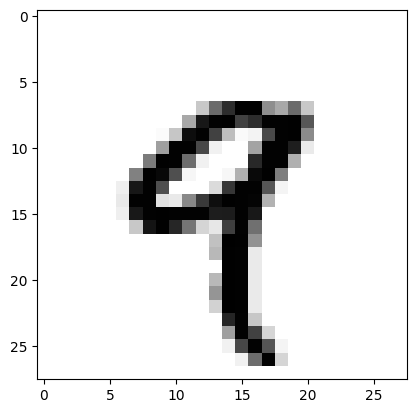

In [14]:
import matplotlib.pyplot as plt

digit = train_images[4] #원본에서 5번쨰 이미지 추출 저장
plt.imshow(digit, cmap=plt.cm.binary) #2차원 배열 숫자 픽셀로 바꿔 이미지 표현
#cmap=plt.cm.binary=색상 맵 흑백 지정
plt.show()

In [15]:
train_labels[4] #정답 레이블 모음
#인덱스 4=5번째 데이터

np.uint8(9)

#### Manipulating tensors in NumPy

In [17]:
my_slice = train_images[10:100] ##10-99까지 추출
my_slice.shape

(90, 28, 28)

In [19]:
my_slice = train_images[10:100, :, :]
#10-99추출+ 이미지 가로 세로 전체 영역 선택
my_slice.shape

(90, 28, 28)

In [18]:
my_slice = train_images[10:100, 0:28, 0:28]
my_slice.shape

(90, 28, 28)

In [20]:
my_slice = train_images[:, 14:, 14:]
#모든 이미지 대상  픽셀은 14-끝ㅏㄲ지

In [21]:
my_slice = train_images[:, 7:-7, 7:-7]
#모든 이미지 대상+위아래 좌우에서 7픽셀씩 잘라둠

#### The notion of data batches

In [22]:
batch = train_images[:128]

In [23]:
batch = train_images[128:256]

In [24]:
n = 3
batch = train_images[128 * n : 128 * (n + 1)]

#### Real-world examples of data tensors

##### Vector data

##### Timeseries data or sequence data

##### Image data

##### Video data

### The gears of neural networks: Tensor operations

#### Element-wise operations

In [25]:
def naive_relu(x):
    assert len(x.shape) == 2 #입력받은 데이터 무조건 2차원 행렬이어야함
    x = x.copy() #배열  복제
    for i in range(x.shape[0]): #모든 행 순회
        for j in range(x.shape[1]): #모든 열 순회
            x[i, j] = max(x[i, j], 0)
            #relu연산 적용 원소의 값과 비교해 0보다 적으면 0, 크면 그대로
    return x

In [26]:
def naive_add(x, y):
    assert len(x.shape) == 2 #입력받은 데이터 무조건 2차원 배열
    assert x.shape == y.shape # 크기 일치 검사->다르면 에러
    x = x.copy() #배열 복제
    for i in range(x.shape[0]):
        for j in range(x.shape[1]):
            x[i, j] += y[i, j]
             #행 열 순회하는 이중반복문->두 행렬 동일 위치 원소끼리 덧셈
    return x

In [27]:
import time

x = np.random.random((20, 100)) #무작위 행렬 생성
y = np.random.random((20, 100))

t0 = time.time() #현재 시각 기록
for _ in range(1000): #반복 연산 수행
    z = x + y
    z = np.maximum(z, 0.0) #0보다 작은 음수 값 모두 0으로 변환
print("Took: {0:.2f} s".format(time.time() - t0)) #소요 시간 출력

Took: 0.01 s


In [28]:
t0 = time.time()
for _ in range(1000): #for문 1000번 실행
    z = naive_add(x, y) #파이썬 이중 반복문 두 행렬 원소끼리 더함
    z = naive_relu(z) #결과 행렬에 relu연산 적용
print("Took: {0:.2f} s".format(time.time() - t0)) #소요 시간 계산
# 앞선 소요시간보다 오래걸린 이유: for문의 실행 속도 때문임

Took: 1.53 s


#### Broadcasting

In [29]:
import numpy as np

X = np.random.random((32, 10))
y = np.random.random((10,))

In [30]:
y = np.expand_dims(y, axis=0)
# y에 새로운 차원 추가해주는 함수
# axis=0-> 가장 첫번째 자리에 새로운 1차원 공간 끼워넣기

In [31]:
Y = np.tile(y, (32, 1))

In [32]:
def naive_add_matrix_and_vector(x, y):
    assert len(x.shape) == 2 # x는 2차원, y는 1차원 이어야함
    assert len(y.shape) == 1
    assert x.shape[1] == y.shape[0] #행렬 열 개수 벡터 원소개수 일치 확인
    x = x.copy()
    for i in range(x.shape[0]): #이중 반복문
    #모든 행 열 순회하면서 각 행의 동일한 열 번호에 해당하는 벡터 원소 더해줌
        for j in range(x.shape[1]):
            x[i, j] += y[j]
    return x

In [33]:
import numpy as np

x = np.random.random((64, 3, 32, 10)) # 64개 배치, 3개 채널, 32^2 픽셀, 10개 특성
y = np.random.random((32, 10)) #
z = np.maximum(x, y) # 브로드캐스팅 통한 최댓값 연산
#브로드캐스팅 통해 x와 크기 똑같은 z 만들어짐

#### Tensor product

In [36]:
x = np.random.random((32,)) #1차원 백터 무작위 생성
y = np.random.random((32,))

z = np.matmul(x, y) #행렬곱셈 or 내적
z = x @ y #행렬 곱셈 연산자

In [40]:
def naive_vector_product(x, y):
    assert len(x.shape) == 1 #차원 검사
    assert len(y.shape) == 1
    assert x.shape[0] == y.shape[0] # 길이 일치 검사
    z = 0.0 #결과 변수 초기화
    for i in range(x.shape[0]):
      #벡터의 길이만큼 반복문 돌며 동일한 인덱스에 있는 원소끼리 서로 곱
        z += x[i] * y[i]
    return z

In [41]:
def naive_matrix_vector_product(x, y):
    assert len(x.shape) == 2
    assert len(y.shape) == 1
    assert x.shape[1] == y.shape[0]
    z = np.zeros(x.shape[0]) #결과 벡터 초기화
    for i in range(x.shape[0]): # 행렬의 각 행 벡터의 원소 곱한 뒤 더해줌
        for j in range(x.shape[1]):
            z[i] += x[i, j] * y[j]
    return z

In [42]:
def naive_matrix_vector_product(x, y):
    z = np.zeros(x.shape[0])
    for i in range(x.shape[0]):
        z[i] = naive_vector_product(x[i, :], y)
    return z

In [43]:
def naive_matrix_product(x, y):
    assert len(x.shape) == 2
    assert len(y.shape) == 2
    assert x.shape[1] == y.shape[0]
    z = np.zeros((x.shape[0], y.shape[1])) # 결과 행렬 초기화
    for i in range(x.shape[0]): #행렬 곱셈 연산
        for j in range(y.shape[1]):
            row_x = x[i, :]
            column_y = y[:, j]
            z[i, j] = naive_vector_product(row_x, column_y)
            #추출한 x y의 행 열을 앞서 만들었던 백터 내적 함수에 곱한 뒤 결과값 저장
    return z

#### Tensor reshaping

In [44]:
train_images = train_images.reshape((60000, 28 * 28))

In [45]:
x = np.array([[0., 1.],
              [2., 3.],
              [4., 5.]])
x.shape

(3, 2)

In [46]:
x = x.reshape((6, 1))
x

array([[0.],
       [1.],
       [2.],
       [3.],
       [4.],
       [5.]])

In [47]:
x = x.reshape((2, 3))
x
#2차원 행렬로 재구성

array([[0., 1., 2.],
       [3., 4., 5.]])

In [48]:
x = np.zeros((300, 20))
x = np.transpose(x)
x.shape

(20, 300)

#### Geometric interpretation of tensor operations

#### A geometric interpretation of deep learning

### The engine of neural networks: Gradient-based optimization

#### What's a derivative?

#### Derivative of a tensor operation: The gradient

#### Stochastic gradient descent

#### Chaining derivatives: The Backpropagation algorithm

##### The chain rule

##### Automatic differentiation with computation graphs

### Looking back at our first example

In [ ]:
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
train_images = train_images.reshape((60000, 28 * 28))
train_images = train_images.astype("float32") / 255
test_images = test_images.reshape((10000, 28 * 28))
test_images = test_images.astype("float32") / 255

In [ ]:
model = keras.Sequential(
    [
        layers.Dense(512, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ]
)

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [ ]:
model.fit(
    train_images,
    train_labels,
    epochs=5,
    batch_size=128,
)

#### Reimplementing our first example from scratch

##### A simple Dense class

In [1]:
import keras
from keras import ops

class NaiveDense: #기본 밀집 층 정의
    def __init_(self, input_size, output_size, activation=None):#설정 초기화
        self.activation = activation #전달받은 활성화함수 저장
        self.W = keras.Variable( #가중치 행렬 만듦
            shape=(input_size, output_size), initializer="uniform" #가중치 기초값 균등분포
        ) #가중치 크기를 입력 크기 , 출력 크기에 맞게 설정
        self.b = keras.Variable(shape=(output_size,), initializer="zeros")
        #각 뉴런에 더해질 편향 벡터 설정
    def __call__(self, inputs):#함수처럼 호출
        x = ops.matmul(inputs, self.W) #입력 데이터*가중치행렬
        x = x + self.b #편향 더해줌
        if self.activation is not None: #활성화함수가 지정돼있지 않다면
            x = self.activation(x) #x를 통과시켜 변형
        return x

    @property
    def weights(self): #학습하면서 업데이트할 가중치,편향을 리스트로 보여줌
        return [self.W, self.b]

##### A simple Sequential class

In [ ]:
class NaiveSequential:
    def __init__(self, layers):
        self.layers = layers

    def __call__(self, inputs):
        x = inputs
        for layer in self.layers:
            x = layer(x) #첫째 층의 출력이 둘째 층의 입력이됨
        return x

    @property
    def weights(self):
        weights = [] #모델 전체에 포함된 가중치들을 모아둘 빈 리스트 만듦
        for layer in self.layers:
          #모델 안 모든 층 확인하면서 각 층이 가지고 있는 가중치 리스트 꺼내어 누적
            weights += layer.weights
        return weights

In [ ]:
model = NaiveSequential(
    [
        NaiveDense(input_size=28 * 28, output_size=512, activation=ops.relu),
        NaiveDense(input_size=512, output_size=10, activation=ops.softmax),
    ]
)
assert len(model.weights) == 4

##### A batch generator

In [ ]:
import math

class BatchGenerator:
    def __init__(self, images, labels, batch_size=128):
        assert len(images) == len(labels)
        self.index = 0 #시작 인덱스 0으로 초기화
        self.images = images #이미지 레이블 저장
        self.labels = labels
        self.batch_size = batch_size
        self.num_batches = math.ceil(len(images) / batch_size) #총 배치 수 계산

    def next(self):
        images = self.images[self.index : self.index + self.batch_size] #현재 인덱스부터 크기만큼 잘라냄
        labels = self.labels[self.index : self.index + self.batch_size] #잘라낸 이미지 레이블 반환
        self.index += self.batch_size
        return images, labels

#### Running one training step

##### The weight update step

In [ ]:
learning_rate = 1e-3

def update_weights(gradients, weights):
    for g, w in zip(gradients, weights):
        w.assign(w - g * learning_rate)

In [ ]:
from keras import optimizers

optimizer = optimizers.SGD(learning_rate=1e-3)

def update_weights(gradients, weights):
    optimizer.apply_gradients(zip(gradients, weights))

##### Gradient computation

In [ ]:
%%backend tensorflow
import tensorflow as tf

x = tf.zeros(shape=())
with tf.GradientTape() as tape:
    y = 2 * x + 3
grad_of_y_wrt_x = tape.gradient(y, x)

In [ ]:
%%backend tensorflow
def one_training_step(model, images_batch, labels_batch):
    with tf.GradientTape() as tape:
        predictions = model(images_batch)
        loss = ops.sparse_categorical_crossentropy(labels_batch, predictions)
        average_loss = ops.mean(loss)
    gradients = tape.gradient(average_loss, model.weights)
    update_weights(gradients, model.weights)
    return average_loss

#### The full training loop

In [ ]:
%%backend tensorflow
def fit(model, images, labels, epochs, batch_size=128):
    for epoch_counter in range(epochs):
        print(f"Epoch {epoch_counter}")
        batch_generator = BatchGenerator(images, labels)
        for batch_counter in range(batch_generator.num_batches):
            images_batch, labels_batch = batch_generator.next()
            loss = one_training_step(model, images_batch, labels_batch)
            if batch_counter % 100 == 0:
                print(f"loss at batch {batch_counter}: {loss:.2f}")

In [ ]:
%%backend tensorflow
from keras.datasets import mnist

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

train_images = train_images.reshape((60000, 28 * 28))
train_images = train_images.astype("float32") / 255
test_images = test_images.reshape((10000, 28 * 28))
test_images = test_images.astype("float32") / 255

fit(model, train_images, train_labels, epochs=10, batch_size=128)

#### Evaluating the model

In [ ]:
%%backend tensorflow
predictions = model(test_images) #테스트용 이미지 데이터 모델에 통과시켜 예측결과 출력
predicted_labels = ops.argmax(predictions, axis=1) #가장 높은 값이 위치한 인덱스 찾아 최종 예측 라벨로 확정
matches = predicted_labels == test_labels #예측 라벨과 정답라벨 비교 불리언 배열 만듦
f"accuracy: {ops.mean(matches):.2f}" #t f 평균 = 정확도 구함